In [1]:
%pip -qq install osmnx contextily

In [19]:
from pathlib import Path

import pandas as pd
import json
import os
import folium
import geopandas as gpd
from folium.plugins import Draw

import networkx as nx
import osmnx as ox
import contextily as ctx

from google.colab import drive, files

import matplotlib.pyplot as plt

In [47]:
drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/quantum_road_scheduling")
OUTPUT_DIR = PROJECT_DIR / "output"
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PROJECT_DIR

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


PosixPath('/content/drive/MyDrive/quantum_road_scheduling')

In [4]:
GRAPH_EXTRACTED = True # first time run with no selected area - make it False !

montreal_center = (45.5019, -73.5674)

origin = (45.40917802385951, -73.65906344074625)  # bridge
destination = (45.34599185120908, -73.7638231)    # hospital

threshold_factor = 1.2 # unacceptable detour delay

In [15]:

m = folium.Map(
    location=montreal_center,
    zoom_start=10,
    tiles=None
)

folium.TileLayer(
    tiles="https://{s}.tile.opentopomap.org/{z}/{x}/{y}.png",
    attr="Map data © OpenStreetMap contributors | Map style © OpenTopoMap (CC-BY-SA)",
    name="OpenTopoMap",
    subdomains="abc"
).add_to(m)

if not GRAPH_EXTRACTED: # export and save a graph file in project dir

    Draw(
        export=True,
        filename="study_area.geojson",
        position="topleft",
        draw_options={
            "polyline": False,
            "circle": False,
            "circlemarker": False,
            "marker": False
        }
    ).add_to(m)

else:
    with open(PROJECT_DIR / "study_area.geojson") as f:
        geo = json.load(f)

    ring = geo["features"][0]["geometry"]["coordinates"][0]

    # Convert GeoJSON (longitude, latitude) to Folium (latitude, longitude)
    corners = [[lat, lon] for lon, lat in ring]

    folium.Polygon(
        locations=corners,
        color="red",
        weight=3,
        fill=False
    ).add_to(m)

    for i, corner in enumerate(corners[:-1], 1):
        folium.Marker(corner, tooltip=f"P{i}").add_to(m)

    m.fit_bounds(corners)

m

In [16]:
STUDY_AREA_FILE = PROJECT_DIR / "study_area.geojson"

study_area = gpd.read_file(STUDY_AREA_FILE).to_crs("EPSG:4326")
polygon = study_area.geometry.union_all()

study_area

,geometry
0,"POLYGON ((-73.65765 45.41036, -73.68409 45.420..."


In [20]:
G = ox.graph_from_polygon(
    polygon,
    network_type="drive",
    simplify=True,
    retain_all=False
)

G = ox.routing.add_edge_speeds(G)
G = ox.routing.add_edge_travel_times(G)

In [21]:
# save point
GRAPHML_FILE = PROJECT_DIR / "network.graphml"
GPKG_FILE = PROJECT_DIR / "network.gpkg"

ox.io.save_graphml(G, GRAPHML_FILE)

ox.io.save_graph_geopackage(
    G,
    GPKG_FILE,
    directed=True
)


In [ ]:
# restart point
GRAPHML_FILE = PROJECT_DIR / "network.graphml"
GPKG_FILE = PROJECT_DIR / "network.gpkg"

if os.path.exists(GRAPHML_FILE):
    G = ox.io.load_graphml(GRAPHML_FILE)

In [23]:
nodes, edges = ox.graph_to_gdfs(G)
print(f"Nodes: {G.number_of_nodes():,}")
print(f"Edges: {G.number_of_edges():,}")

Nodes: 1,889
Edges: 4,976


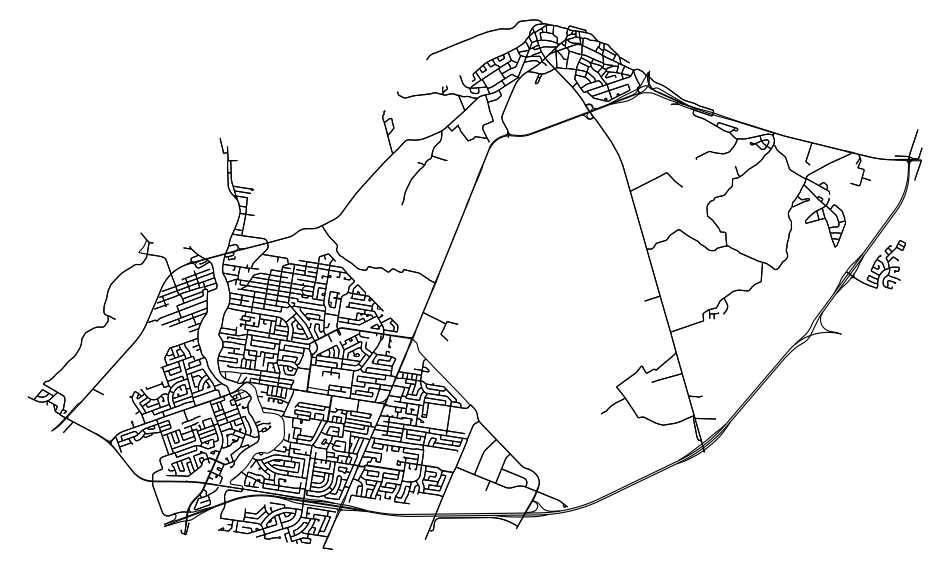

In [25]:
fig, ax = ox.plot_graph(
    G,
    node_size=0,
    edge_linewidth=0.8,
    figsize=(12, 12),
    bgcolor="white",
    edge_color="black"
)

In [26]:
# sanity check
edges["highway_group"] = edges["highway"].apply(
    lambda x: ", ".join(x) if isinstance(x, list) else x
)

edges.groupby("highway_group")["speed_kph"].agg(
    ["count", "mean", "min", "max"]
).sort_values("count", ascending=False)

,count,mean,min,max
highway_group,,,,
residential,3695,38.989102,10.0,50.0
tertiary,857,39.480338,30.0,70.0
trunk,124,59.032258,50.0,70.0
unclassified,60,43.035088,30.0,50.0
primary,50,64.400000,50.0,70.0
motorway_link,38,99.210526,70.0,100.0
tertiary_link,38,37.894737,30.0,70.0
secondary,32,52.500000,40.0,70.0
motorway,25,98.200000,70.0,100.0


In [27]:
G_route = ox.truncate.largest_component(G, strongly=True) # drop invalid edges and dead ends

origin_node = ox.distance.nearest_nodes(
    G_route,
    X=origin[1],
    Y=origin[0]
)

destination_node = ox.distance.nearest_nodes(
    G_route,
    X=destination[1],
    Y=destination[0]
)

print(f"Routing graph nodes: {G_route.number_of_nodes():,}")
print(f"Routing graph edges: {G_route.number_of_edges():,}")

print(
    "Origin → Destination:",
    nx.has_path(G_route, origin_node, destination_node)
)

Routing graph nodes: 1,884
Routing graph edges: 4,966
Origin → Destination: True


In [28]:
baseline_route = ox.routing.shortest_path(
    G_route,
    origin_node,
    destination_node,
    weight="travel_time"
)

baseline_edges = ox.routing.route_to_gdf(
    G_route,
    baseline_route,
    weight="travel_time"
)

baseline_distance_km = baseline_edges["length"].sum() / 1000
baseline_time_s = baseline_edges["travel_time"].sum()

threshold_time_s = baseline_time_s * threshold_factor


print(f"Distance: {baseline_distance_km:.2f} km")
print(f"Free-flow travel time: {baseline_time_s / 60 :.1f} min")
print(f"Critical threshold (unacceptable detour delay): {threshold_time_s / 60 :.1f} min")

Distance: 12.77 km
Free-flow travel time: 12.4 min
Critical threshold (unacceptable detour delay): 14.9 min


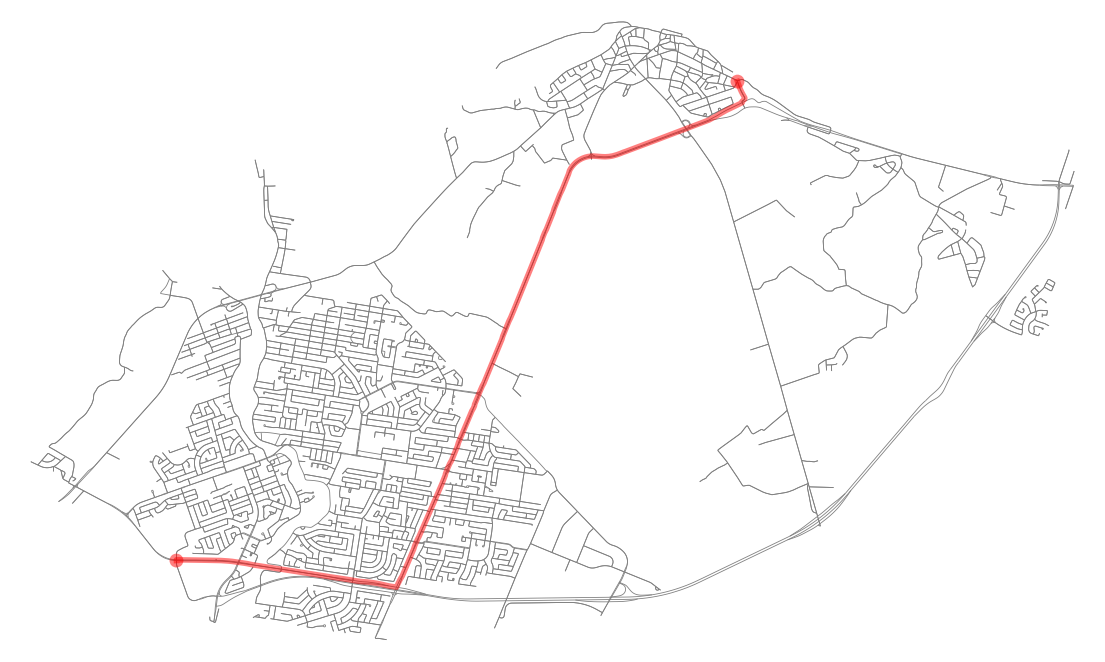

In [30]:
# Fastest way
fig, ax = ox.plot_graph_route(
    G_route,
    baseline_route,
    route_linewidth=4,
    node_size=0,
    edge_linewidth=0.6,
    edge_color="gray",
    bgcolor="white",
    figsize=(14, 14)
)

In [31]:
# helpers
def route_units(route):
    units = [
        tuple(sorted((u, v)))
        for u, v in zip(route[:-1], route[1:])
    ]
    return list(dict.fromkeys(units))


def remove_units(G, units):
    H = G.copy()

    for u, v in units:
        if H.has_edge(u, v):
            H.remove_edges_from(
                [(u, v, k) for k in list(H[u][v].keys())]
            )

        if H.has_edge(v, u):
            H.remove_edges_from(
                [(v, u, k) for k in list(H[v][u].keys())]
            )

    return H


def reroute_after(units):
    H = remove_units(G_route, units)

    try:
        route = nx.shortest_path(
            H,
            origin_node,
            destination_node,
            weight="travel_time"
        )
    except nx.NetworkXNoPath:
        return None, None

    route_edges = ox.routing.route_to_gdf(
        H,
        route,
        weight="travel_time"
    )

    travel_time = route_edges["travel_time"].sum()

    return route, travel_time

In [34]:
baseline_units = route_units(baseline_route)

# identifying critial edges

critical_single_units = set()
single_reroutes = {}
single_records = []

for unit in baseline_units:

    route_new, time_new = reroute_after([unit])

    if route_new is None:
        critical = True
        status = "unreachable"
        increase_pct = None
        new_time_min = None

    else:
        increase_pct = (time_new / baseline_time_s - 1) * 100
        critical = time_new > threshold_time_s
        status = "critical" if critical else "ok"
        new_time_min = time_new / 60

    if critical:
        critical_single_units.add(unit)
    else:
        single_reroutes[unit] = route_new

    single_records.append({
        "size": 1,
        "unit_1": unit,
        "unit_2": None,
        "unit_3": None,
        "status": status,
        "new_time_min": new_time_min,
        "increase_pct": increase_pct
    })

In [35]:
single_results = pd.DataFrame(single_records)

single_results.sort_values(
    "increase_pct",
    ascending=False,
    na_position="first"
).head()

,size,unit_1,unit_2,unit_3,status,new_time_min,increase_pct
8,1,"(129972428, 4859748087)",None,None,critical,14.901902,20.075605
9,1,"(3487892169, 4859748087)",None,None,critical,14.901902,20.075605
10,1,"(3487892169, 8085198676)",None,None,critical,14.901902,20.075605
7,1,"(129972428, 8085198710)",None,None,critical,14.901902,20.075605
11,1,"(7924491174, 8085198676)",None,None,critical,14.901902,20.075605


In [36]:
# identifying critial pairs

tested_pairs = set()
pair_records = []
pair_reroutes = {}

for unit_a, route_a in single_reroutes.items():

    for unit_b in route_units(route_a):

        if unit_b == unit_a:
            continue

        if unit_b in critical_single_units:
            continue

        pair = tuple(sorted((unit_a, unit_b)))

        if pair in tested_pairs:
            continue

        tested_pairs.add(pair)

        route_new, time_new = reroute_after(pair)

        if route_new is None:
            critical = True
            status = "unreachable"
            increase_pct = None
            new_time_min = None

        else:
            increase_pct = (time_new / baseline_time_s - 1) * 100
            critical = time_new > threshold_time_s
            status = "critical" if critical else "ok"
            new_time_min = time_new / 60

        if critical:
            pair_records.append({
                "size": 2,
                "unit_1": pair[0],
                "unit_2": pair[1],
                "unit_3": None,
                "status": status,
                "new_time_min": new_time_min,
                "increase_pct": increase_pct
            })
        else:
            pair_reroutes[pair] = route_new

In [37]:
critical_pairs = pd.DataFrame(
    pair_records,
    columns=[
        "size",
        "unit_1",
        "unit_2",
        "unit_3",
        "status",
        "new_time_min",
        "increase_pct"
    ]
)

critical_pairs.sort_values(
    "increase_pct",
    ascending=False,
    na_position="first"
).head()

,size,unit_1,unit_2,unit_3,status,new_time_min,increase_pct
3,2,"(3495233768, 7939009570)","(4224829870, 8536815560)",None,critical,15.438979,24.403232
2,2,"(3495233768, 13510598398)","(4224829870, 8536815560)",None,critical,15.438979,24.403232
4,2,"(4224829870, 8536815560)","(7939009570, 10295557258)",None,critical,15.438979,24.403232
5,2,"(137980893, 10295557258)","(4224829870, 8536815560)",None,critical,15.438979,24.403232
13,2,"(128919678, 139880600)","(4224829870, 8536815560)",None,critical,15.366832,23.821890


In [38]:
RESULT_COLUMNS = [
    "size",
    "unit_1",
    "unit_2",
    "unit_3",
    "status",
    "new_time_min",
    "increase_pct"
]

critical_sets = pd.DataFrame(
    single_records + pair_records,
    columns=RESULT_COLUMNS
)

critical_sets = critical_sets[
    critical_sets["status"].isin(["critical", "unreachable"])
].reset_index(drop=True)

critical_sets.head()

,size,unit_1,unit_2,unit_3,status,new_time_min,increase_pct
0,1,"(129972428, 8085198710)",None,None,critical,14.901902,20.075605
1,1,"(129972428, 4859748087)",None,None,critical,14.901902,20.075605
2,1,"(3487892169, 4859748087)",None,None,critical,14.901902,20.075605
3,1,"(3487892169, 8085198676)",None,None,critical,14.901902,20.075605
4,1,"(7924491174, 8085198676)",None,None,critical,14.901902,20.075605


In [39]:
# Reconstruct alternative routes associated with critical pairs
pair_support_routes = []

for _, row in critical_pairs.iterrows():

    a = row["unit_1"]
    b = row["unit_2"]

    # Check reroute after closing A
    if a in single_reroutes:
        route = single_reroutes[a]

        if b in route_units(route):
            pair_support_routes.append(route)

    # Check reroute after closing B
    if b in single_reroutes:
        route = single_reroutes[b]

        if a in route_units(route):
            pair_support_routes.append(route)

pair_support_routes = list(
    {tuple(route): route for route in pair_support_routes}.values()
)

print(f"Alternative routes to display: {len(pair_support_routes)}")

Alternative routes to display: 15


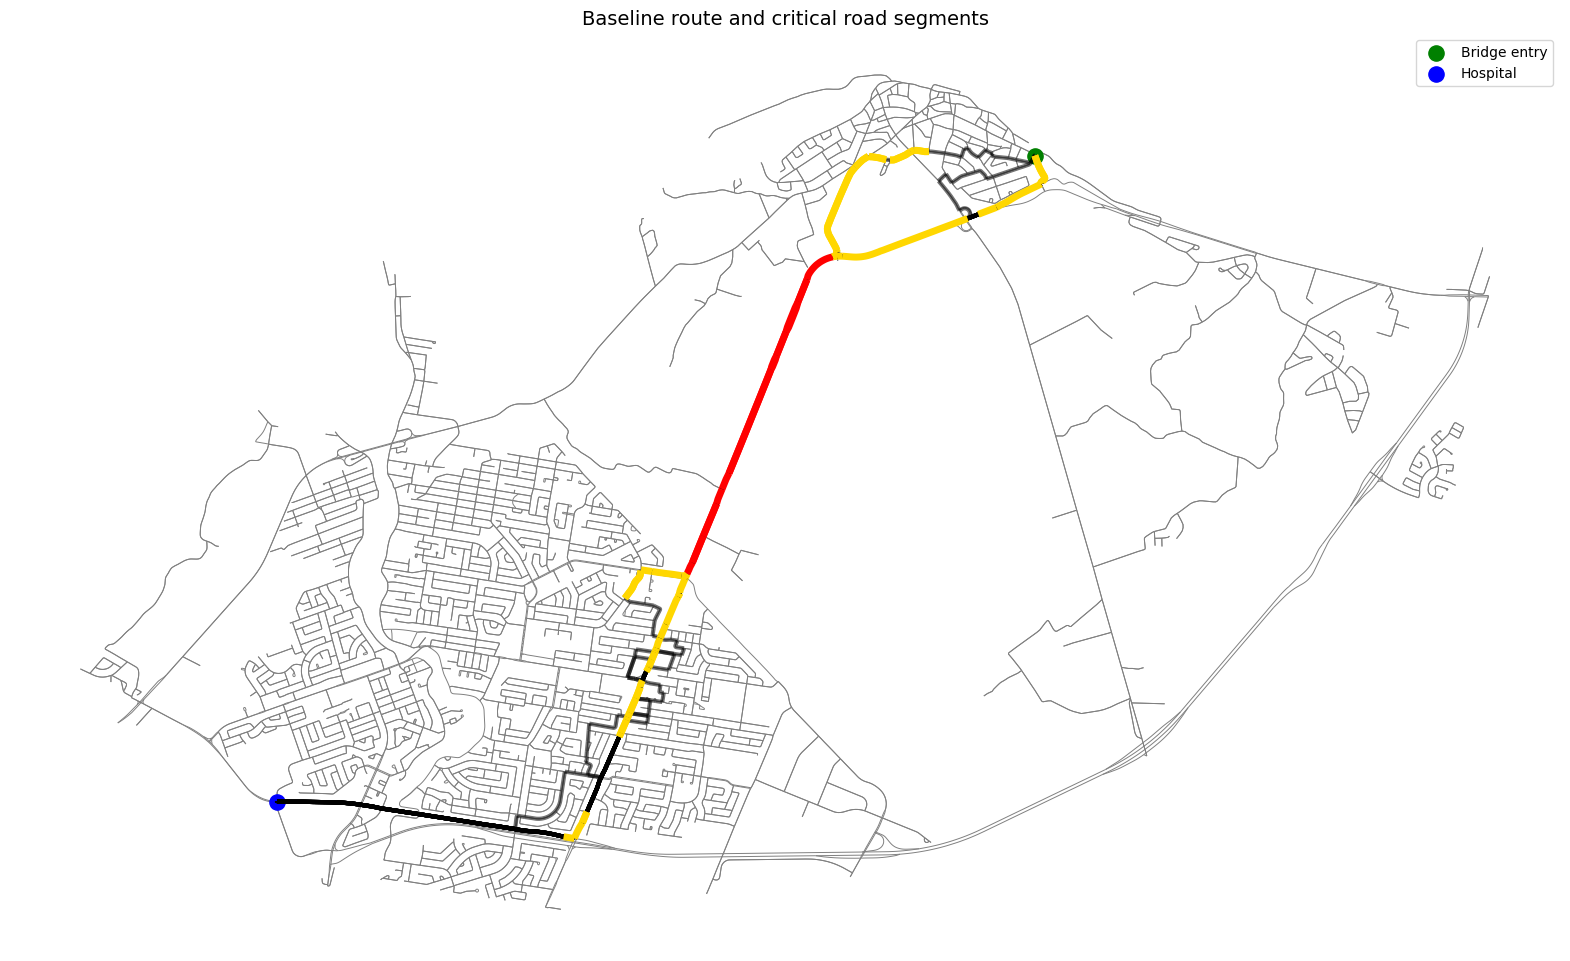

In [49]:
fig, ax = plt.subplots(figsize=(20, 20))

edges_plot = ox.graph_to_gdfs(G_route, nodes=False)

# All road units that participate in at least one critical pair
pair_units = set()

if not critical_pairs.empty:
    pair_units.update(critical_pairs["unit_1"].dropna())
    pair_units.update(critical_pairs["unit_2"].dropna())

# Select graph edges belonging to each category
single_edges_plot = edges_plot[
    [
        tuple(sorted((u, v))) in critical_single_units
        for u, v, k in edges_plot.index
    ]
]

pair_edges_plot = edges_plot[
    [
        tuple(sorted((u, v))) in pair_units
        for u, v, k in edges_plot.index
    ]
]

# Entire network
edges_plot.plot(
    ax=ax,
    color="gray",
    linewidth=0.7,
    zorder=1
)

# Alternative routes associated with critical pairs
for route in pair_support_routes:

    route_gdf = ox.routing.route_to_gdf(
        G_route,
        route,
        weight="travel_time"
    )

    route_gdf.plot(
        ax=ax,
        color="black",
        linewidth=3,
        alpha=0.55,
        zorder=2
    )

# Fastest baseline route
baseline_edges.plot(
    ax=ax,
    color="black",
    linewidth=3,
    zorder=3
)

# Critical singles
single_edges_plot.plot(
    ax=ax,
    color="red",
    linewidth=5,
    zorder=4
)

# Actual members of critical pairs
pair_edges_plot.plot(
    ax=ax,
    color="gold",
    linewidth=5,
    zorder=5
)

ax.set_axis_off()
ax.set_title(
    "Baseline route and critical road segments",
    fontsize=14
)

# Start and end points
ax.scatter(
    G_route.nodes[origin_node]["x"],
    G_route.nodes[origin_node]["y"],
    s=120,
    color="green",
    label="Bridge entry"
)

ax.scatter(
    G_route.nodes[destination_node]["x"],
    G_route.nodes[destination_node]["y"],
    s=120,
    color="blue",
    label="Hospital"
)

ax.legend()

plt.savefig(
    OUTPUT_DIR / "critical_edges_map.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [42]:
critical_sets.to_csv(
    OUTPUT_DIR / "critical_sets.csv",
    index=False
)

In [43]:
edges_map = edges_plot.to_crs(epsg=3857)
baseline_map = baseline_edges.to_crs(epsg=3857)
single_map = single_edges_plot.to_crs(epsg=3857)
pair_map = pair_edges_plot.to_crs(epsg=3857)

In [44]:
pair_support_gdfs = []

for route in pair_support_routes:
    route_gdf = ox.routing.route_to_gdf(
        G_route,
        route,
        weight="travel_time"
    ).to_crs(epsg=3857)

    pair_support_gdfs.append(route_gdf)

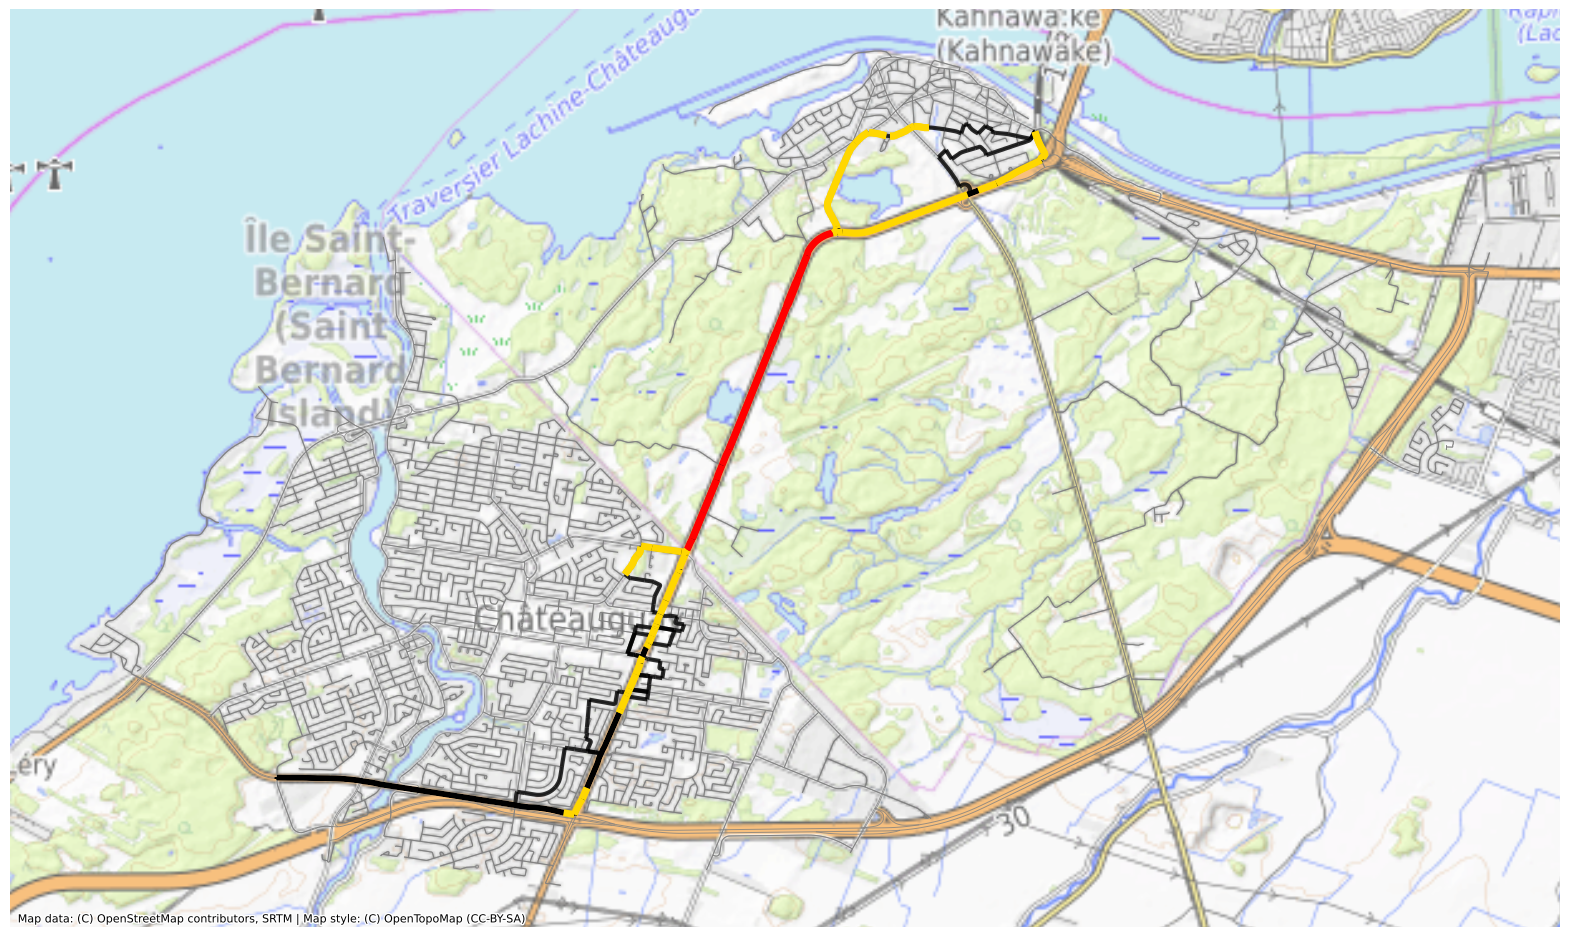

In [48]:
fig, ax = plt.subplots(figsize=(20, 20))

# Full network
edges_map.plot(
    ax=ax,
    color="gray",
    linewidth=0.7,
    alpha=0.8,
    zorder=2
)

# Alternative routes
for route_gdf in pair_support_gdfs:
    route_gdf.plot(
        ax=ax,
        color="black",
        linewidth=3,
        alpha=0.8,
        zorder=3
    )

# Fastest route
baseline_map.plot(
    ax=ax,
    color="black",
    linewidth=4,
    zorder=4
)

# Critical singles
single_map.plot(
    ax=ax,
    color="red",
    linewidth=5,
    zorder=5
)

# Critical-pair members
pair_map.plot(
    ax=ax,
    color="gold",
    linewidth=5,
    zorder=6
)

# Basemap
ctx.add_basemap(
    ax,
    source=ctx.providers.OpenTopoMap,
    zoom="auto",
    alpha=0.6
)

ax.set_axis_off()

plt.savefig(
    OUTPUT_DIR / "critical_edges_map_with_background.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()